# SmartFactory — Part B: Casting Inspection and Part C: Comparison

## 1. Environment and Reproducibility

In [1]:
from pathlib import Path
from copy import deepcopy
from time import perf_counter
import hashlib
import random
import platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, fbeta_score, roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay, classification_report, precision_recall_curve,
    matthews_corrcoef, log_loss,
)

In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ROOT = Path.cwd()
if not (ROOT / 'data').is_dir():
    raise FileNotFoundError('The notebook and its data folder must share a directory.')
OUT = ROOT / 'outputs' / 'part_b'
MODELS = ROOT / 'models'
OUT.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', palette='colorblind', font_scale=1.05)
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 180, 'axes.spines.top': False,
                      'axes.spines.right': False, 'figure.constrained_layout.use': True})

In [4]:
environment = pd.Series({
    'Python': platform.python_version(), 'Device': str(DEVICE),
    'Processor': platform.machine(), 'Torch threads': torch.get_num_threads(),
    **{p: metadata.version(p) for p in ['numpy', 'pandas', 'scikit-learn', 'torch']},
}, name='Executed environment')
display(environment.to_frame())
environment.to_csv(OUT / 'environment.csv')

,Executed environment
Python,3.12.14
Device,cpu
Processor,x86_64
Torch threads,4
numpy,2.3.5
pandas,2.2.3
scikit-learn,1.8.0
torch,2.14.1


In [5]:
def save_figure(name):
    plt.savefig(OUT / f'{name}.png', bbox_inches='tight')
    plt.show()
    plt.close()

def sync_device():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()

In [6]:
from PIL import Image, ImageOps
from torch.utils.data import Dataset
from torchvision import transforms
from scipy.fft import dctn
from sklearn.model_selection import StratifiedGroupKFold

## 2. Original Casting Photographs and Provenance

In [7]:
image_root = ROOT / 'data' / 'casting'
paths = sorted(image_root.rglob('*.jpeg'))
records = pd.DataFrame({'path': [str(p.relative_to(ROOT)) for p in paths],
                         'label': [int(p.parent.name == 'def_front') for p in paths],
                         'class': [p.parent.name for p in paths]})
assert len(records) == 1300
assert records['label'].value_counts().min() >= 300
scope = pd.Series({
    'Dataset': 'Casting Product Image Data for Quality Inspection — original 512×512 set',
    'Creator': 'Ravirajsinh Dabhi; photographs supported by PILOT TECHNOCAST, Rajkot',
    'Source': 'https://www.kaggle.com/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product',
    'Version': '2; 781 defective and 519 OK images; all 1,300 originals included',
    'Licence': 'CC BY-NC-ND 4.0; source image bytes retained unchanged',
    'Target': '1 = defective casting (fail), 0 = OK casting (pass)',
    'Selection': 'Original photographs avoid the published 300×300 set with pre-applied augmentation',
    'Boundary': 'No part/batch identifiers; unseen-part and unseen-factory generalisation remains unverified',
}, name='Image dataset')
display(scope.to_frame())
display(records.groupby(['label', 'class']).size().to_frame('images'))
scope.to_csv(OUT / 'dataset_scope.csv')

,Image dataset
Dataset,Casting Product Image Data for Quality Inspect...
Creator,Ravirajsinh Dabhi; photographs supported by PI...
Source,https://www.kaggle.com/datasets/ravirajsinh45/...
Version,"2; 781 defective and 519 OK images; all 1,300 ..."
Licence,CC BY-NC-ND 4.0; source image bytes retained u...
Target,"1 = defective casting (fail), 0 = OK casting (..."
Selection,Original photographs avoid the published 300×3...
Boundary,No part/batch identifiers; unseen-part and uns...


,,images
label,class,
0,ok_front,519
1,def_front,781


## 3. Integrity, Duplicates and Stratified Partitions

In [8]:
def inspect_image(relative_path):
    path = ROOT / relative_path
    with Image.open(path) as image:
        image.load()
        pixels = np.asarray(image.convert('L'))
        small = np.asarray(image.convert('L').resize((32, 32)), dtype=float)
        low = dctn(small, norm='ortho')[:8, :8].ravel()[1:]
        phash = low > np.median(low)
        return {'width': image.width, 'height': image.height, 'mode': image.mode,
                'sha256': hashlib.sha256(path.read_bytes()).hexdigest(),
                'pixel_sha256': hashlib.sha256(pixels.tobytes()).hexdigest(),
                'mean_intensity': pixels.mean() / 255,
                'contrast': pixels.std() / 255, 'phash': phash}

audits = [inspect_image(path) for path in records['path']]
audit_frame = pd.DataFrame([{k: v for k, v in a.items() if k != 'phash'} for a in audits])
records = pd.concat([records, audit_frame], axis=1)
assert not records['pixel_sha256'].duplicated().any()
display(records[['width', 'height', 'mode']].value_counts().to_frame('count'))
display(records[['mean_intensity', 'contrast']].describe())

,,,count
width,height,mode,
512,512,RGB,1300


,mean_intensity,contrast
count,1300.000000,1300.000000
mean,0.559636,0.238621
std,0.039759,0.019681
min,0.453252,0.188755
25%,0.528799,0.225052
50%,0.552784,0.237167
75%,0.590299,0.249801
max,0.675082,0.295215


In [9]:
# Group near-identical pHashes before splitting, retaining connected components.
hash_matrix = np.stack([item['phash'] for item in audits])
parents = np.arange(len(records))

def root_group(i):
    while parents[i] != i:
        parents[i] = parents[parents[i]]
        i = parents[i]
    return i

near_pairs = []
for i in range(len(records)):
    distances = np.count_nonzero(hash_matrix[i + 1:] != hash_matrix[i], axis=1)
    for j in np.flatnonzero(distances <= 4) + i + 1:
        parents[root_group(int(j))] = root_group(i)
        near_pairs.append((i, int(j), int(np.count_nonzero(hash_matrix[i] != hash_matrix[j]))))
records['similarity_group'] = [root_group(i) for i in range(len(records))]
print(f'Near-duplicate candidates (pHash distance ≤ 4): {len(near_pairs)}')
display(pd.Series({'similarity_groups': records['similarity_group'].nunique(),
                   'largest_group': records.groupby('similarity_group').size().max(),
                   'mixed_label_groups': (records.groupby('similarity_group')['label'].nunique() > 1).sum()}
                  ).to_frame('Perceptual similarity audit'))
print('Perceptual hashes flag visual similarity, not confirmed shared product identity.')

Near-duplicate candidates (pHash distance ≤ 4): 773
Perceptual hashes flag visual similarity, not confirmed shared product identity.


,Perceptual similarity audit
similarity_groups,805
largest_group,19
mixed_label_groups,12


In [10]:
outer_split = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
train_val_idx, test_idx = next(outer_split.split(
    records, records['label'], records['similarity_group']))
train_val = records.iloc[train_val_idx]
inner_split = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
train_local, val_local = next(inner_split.split(
    train_val, train_val['label'], train_val['similarity_group']))
train_idx, val_idx = train_val_idx[train_local], train_val_idx[val_local]
records['split'] = ''
for name, selected in [('train', train_idx), ('validation', val_idx), ('test', test_idx)]:
    records.loc[selected, 'split'] = name
assert records.groupby('similarity_group')['split'].nunique().max() == 1
assert records['split'].ne('').all()
train_records = records[records['split'] == 'train'].reset_index(drop=True)
val_records = records[records['split'] == 'validation'].reset_index(drop=True)
test_records = records[records['split'] == 'test'].reset_index(drop=True)
split_summary = pd.crosstab(records['split'], records['class'])
display(split_summary)
records.to_csv(OUT / 'image_split_and_audit.csv', index=False)
split_summary.to_csv(OUT / 'split_summary.csv')

class,def_front,ok_front
split,,
test,114,76
train,556,370
validation,111,73


## 4. Training Image Exploration

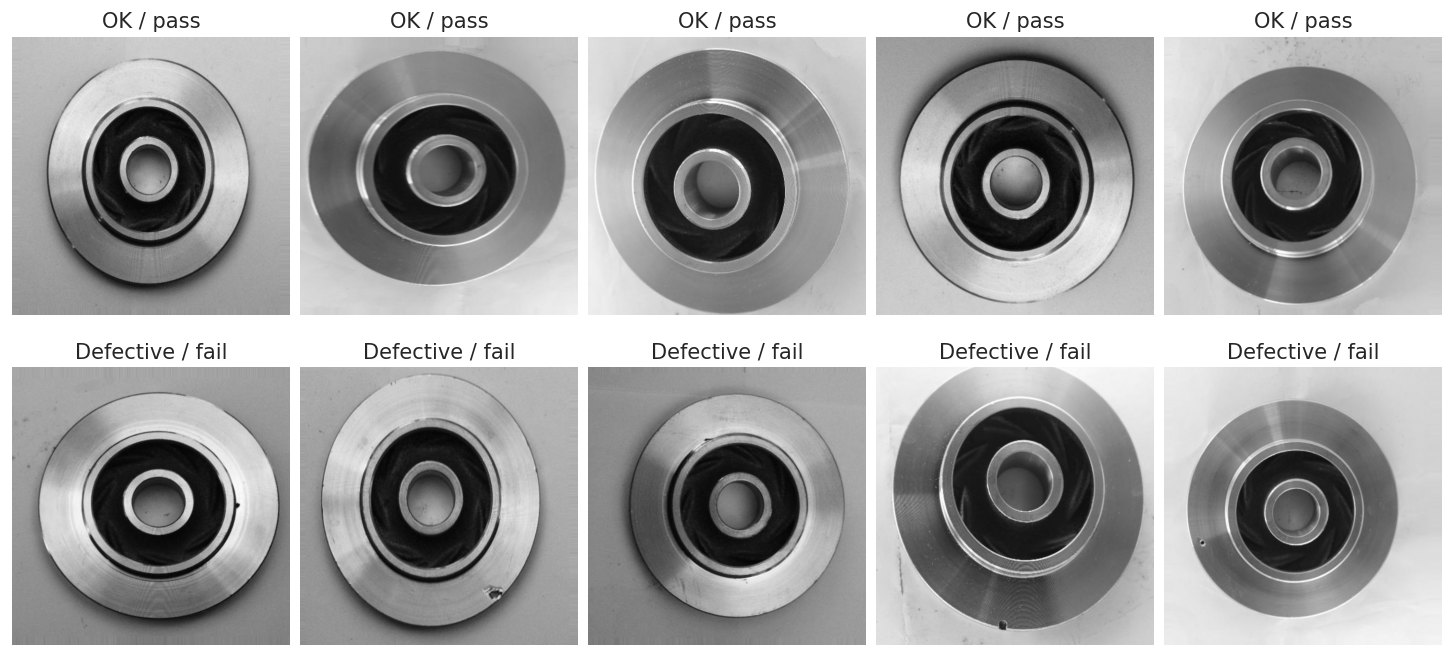

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for row, label in enumerate([0, 1]):
    examples = train_records[train_records['label'] == label].sample(5, random_state=SEED)
    for ax, (_, item) in zip(axes[row], examples.iterrows()):
        with Image.open(ROOT / item['path']) as image:
            ax.imshow(image.convert('L'), cmap='gray', vmin=0, vmax=255)
        ax.set_title('OK / pass' if label == 0 else 'Defective / fail')
        ax.axis('off')
save_figure('01_original_training_examples')

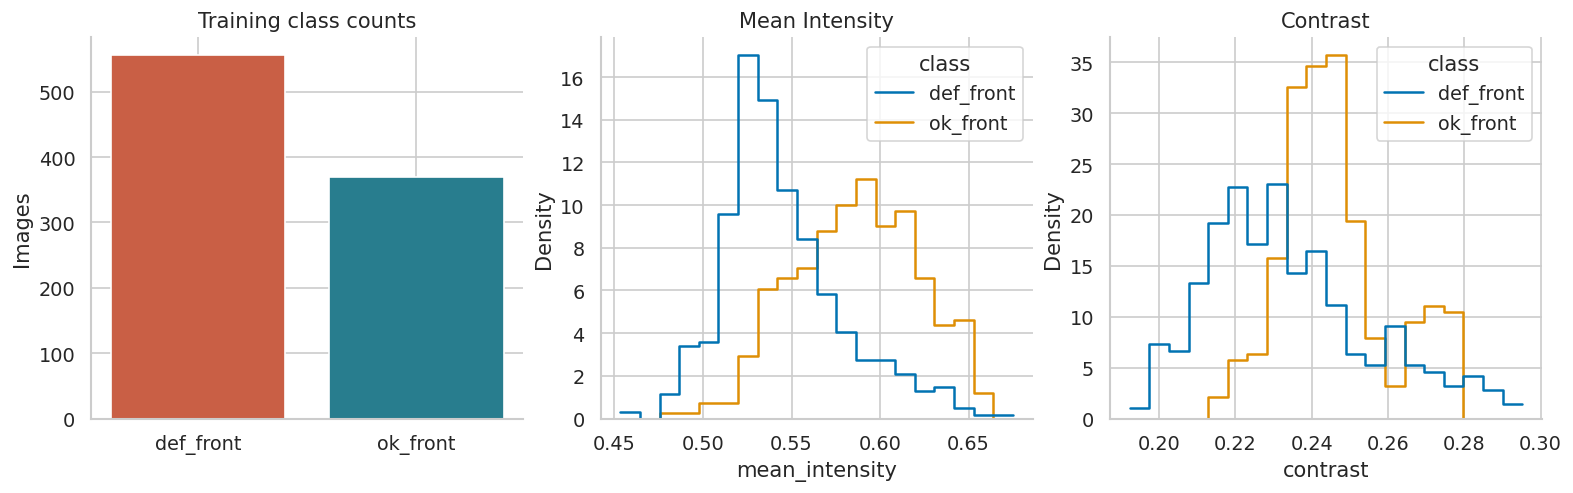

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
counts = train_records['class'].value_counts()
axes[0].bar(counts.index, counts, color=['#c95f45', '#287d8e'])
axes[0].set(ylabel='Images', title='Training class counts')
for ax, feature in zip(axes[1:], ['mean_intensity', 'contrast']):
    sns.histplot(data=train_records, x=feature, hue='class', stat='density',
                 common_norm=False, element='step', fill=False, bins=20, ax=ax)
    ax.set_title(feature.replace('_', ' ').title())
save_figure('02_image_training_distributions')

## 5. Image Preprocessing and Training-Only Augmentation

In [13]:
IMAGE_SIZE = 96
BATCH_SIZE = 32
EPOCHS = 35
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomRotation(10, fill=128),
    transforms.ColorJitter(brightness=0.08, contrast=0.08),
    transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,)),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,)),
])
print('96×96 grayscale; fixed [-1, 1] scaling; validation and test use no augmentation.')
print('Flips and mild rotations preserve casting-defect labels; no crops remove defect regions.')

96×96 grayscale; fixed [-1, 1] scaling; validation and test use no augmentation.
Flips and mild rotations preserve casting-defect labels; no crops remove defect regions.


In [14]:
class CastingDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform
        self.images = []
        for path in self.frame['path']:
            with Image.open(ROOT / path) as image:
                self.images.append(image.convert('L').copy())

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        return (self.transform(self.images[index]),
                torch.tensor(self.frame.iloc[index]['label'], dtype=torch.float32))

train_dataset = CastingDataset(train_records, train_transform)
val_dataset = CastingDataset(val_records, eval_transform)
test_dataset = CastingDataset(test_records, eval_transform)
train_eval_dataset = CastingDataset(train_records, eval_transform)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
train_eval_loader = DataLoader(train_eval_dataset, batch_size=BATCH_SIZE, shuffle=False)

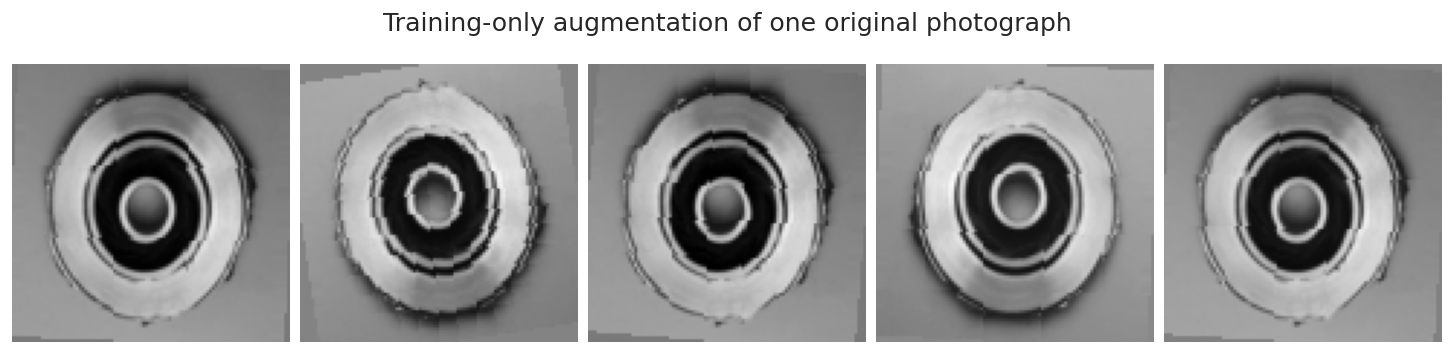

In [15]:
random.seed(SEED)
torch.manual_seed(SEED)
example_image = train_dataset.images[0]
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for ax in axes:
    augmented = train_transform(example_image).squeeze().numpy() * 0.5 + 0.5
    ax.imshow(augmented, cmap='gray', vmin=0, vmax=1)
    ax.axis('off')
fig.suptitle('Training-only augmentation of one original photograph')
save_figure('03_training_augmentation')

## 6. Two CNN Architectures Trained from Scratch

### 6.1. Baseline: Two Convolution–Pooling Blocks

In [16]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(16 * (IMAGE_SIZE // 4) ** 2, 32),
            nn.ReLU(), nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)

### 6.2. Revised: Deeper Filters, Batch Normalisation and Adaptive Pooling

In [17]:
class RevisedCNN(nn.Module):
    def __init__(self):
        super().__init__()
        blocks, inputs = [], 1
        for filters in [16, 32, 64]:
            blocks.extend([nn.Conv2d(inputs, filters, 3, padding=1, bias=False),
                           nn.BatchNorm2d(filters), nn.ReLU(), nn.MaxPool2d(2)])
            inputs = filters
        self.features = nn.Sequential(*blocks)
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((6, 6)), nn.Flatten(),
            nn.Linear(64 * 6 * 6, 32), nn.ReLU(), nn.Dropout(0.35), nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)

architectures = {'Baseline CNN': BaselineCNN, 'Revised CNN': RevisedCNN}
design = pd.DataFrame([
    {'model': name, 'parameters': sum(p.numel() for p in cls().parameters()),
     'design': '2 conv blocks; flattened spatial features' if name == 'Baseline CNN'
               else '3 conv blocks; batch norm; adaptive pooling; dropout'}
    for name, cls in architectures.items()])
display(design)
design.to_csv(OUT / 'architecture_design.csv', index=False)

,model,parameters,design
0,Baseline CNN,296225,2 conv blocks; flattened spatial features
1,Revised CNN,97201,3 conv blocks; batch norm; adaptive pooling; d...


## 7. Loss, Backpropagation and Validation-Based Early Stopping

In [18]:
positive_weight = float((train_records['label'] == 0).sum() /
                        (train_records['label'] == 1).sum())
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(positive_weight, device=DEVICE))
display(pd.Series({
    'Loss': 'Weighted binary cross-entropy with logits; one binary target per image',
    'Stability': 'Combines sigmoid and cross-entropy without taking logs of rounded probabilities',
    'Weight': positive_weight,
    'Optimiser': 'AdamW; learning rate 0.001; weight decay 0.0001',
    'Selection': 'Minimum validation loss; patience 8; at most 35 epochs per architecture',
    'Control': 'Same splits, image size, augmentation, optimiser and epoch budget',
    'Initialisation': 'Random PyTorch initialisation; no pre-trained weights',
}).to_frame('Training design'))

@torch.inference_mode()
def evaluate_network(model, loader):
    model.eval()
    total_loss, probabilities, targets = 0.0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        total_loss += criterion(logits, yb).item() * len(yb)
        probabilities.extend(logits.sigmoid().cpu().numpy())
        targets.extend(yb.cpu().numpy())
    return total_loss / len(targets), np.asarray(probabilities), np.asarray(targets).astype(int)

,Training design
Loss,Weighted binary cross-entropy with logits; one...
Stability,Combines sigmoid and cross-entropy without tak...
Weight,0.665468
Optimiser,AdamW; learning rate 0.001; weight decay 0.0001
Selection,Minimum validation loss; patience 8; at most 3...
Control,"Same splits, image size, augmentation, optimis..."
Initialisation,Random PyTorch initialisation; no pre-trained ...


In [19]:
def train_epoch(model, loader, optimizer):
    model.train()
    total, correct, count = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(yb)
        correct += ((logits.detach() >= 0) == yb.bool()).sum().item()
        count += len(yb)
    return total / count, correct / count

In [20]:
def fit_cnn(model_class):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    model = model_class().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.0001)
    loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED), num_workers=0)
    history, best_loss, stale, best_epoch = [], np.inf, 0, 0
    sync_device()
    started = perf_counter()
    for epoch in range(1, EPOCHS + 1):
        train_loss, train_accuracy = train_epoch(model, loader, optimizer)
        val_loss, probability, truth = evaluate_network(model, val_loader)
        history.append({'epoch': epoch, 'train_loss': train_loss,
                        'validation_loss': val_loss, 'train_accuracy': train_accuracy,
                        'validation_accuracy': accuracy_score(truth, probability >= 0.5),
                        'validation_ap': average_precision_score(truth, probability)})
        if val_loss < best_loss - 0.0001:
            best_loss, best_epoch, stale = val_loss, epoch, 0
            best_state = deepcopy(model.state_dict())
        else:
            stale += 1
        if epoch % 5 == 0:
            print(f'{model_class.__name__}: epoch {epoch}, val loss {val_loss:.4f}', flush=True)
        if stale >= 8:
            break
    sync_device()
    seconds = perf_counter() - started
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_epoch, seconds

### 7.1. Baseline Training

In [21]:
baseline_cnn, baseline_history, baseline_epoch, baseline_seconds = fit_cnn(BaselineCNN)
print(f'Baseline best epoch: {baseline_epoch}; training seconds: {baseline_seconds:.2f}')
baseline_history.to_csv(OUT / 'baseline_training_history.csv', index=False)

BaselineCNN: epoch 5, val loss 0.2797
BaselineCNN: epoch 10, val loss 0.2001
BaselineCNN: epoch 15, val loss 0.2084
BaselineCNN: epoch 20, val loss 0.1486
BaselineCNN: epoch 25, val loss 0.1810
BaselineCNN: epoch 30, val loss 0.1670
BaselineCNN: epoch 35, val loss 0.1134
Baseline best epoch: 34; training seconds: 59.41


### 7.2. Revised Architecture Training

In [22]:
revised_cnn, revised_history, revised_epoch, revised_seconds = fit_cnn(RevisedCNN)
print(f'Revised best epoch: {revised_epoch}; training seconds: {revised_seconds:.2f}')
revised_history.to_csv(OUT / 'revised_training_history.csv', index=False)
cnn_models = {'Baseline CNN': baseline_cnn, 'Revised CNN': revised_cnn}
histories = {'Baseline CNN': baseline_history, 'Revised CNN': revised_history}
epochs = {'Baseline CNN': baseline_epoch, 'Revised CNN': revised_epoch}
seconds = {'Baseline CNN': baseline_seconds, 'Revised CNN': revised_seconds}

RevisedCNN: epoch 5, val loss 0.2477
RevisedCNN: epoch 10, val loss 0.1420
RevisedCNN: epoch 15, val loss 0.3845
RevisedCNN: epoch 20, val loss 0.1046
RevisedCNN: epoch 25, val loss 0.0746
RevisedCNN: epoch 30, val loss 0.0590
RevisedCNN: epoch 35, val loss 0.2264
Revised best epoch: 33; training seconds: 99.66


## 8. Training Curves, Capacity and Architecture Selection

Training curves include augmentation and dropout; validation curves use clean images in eval mode.


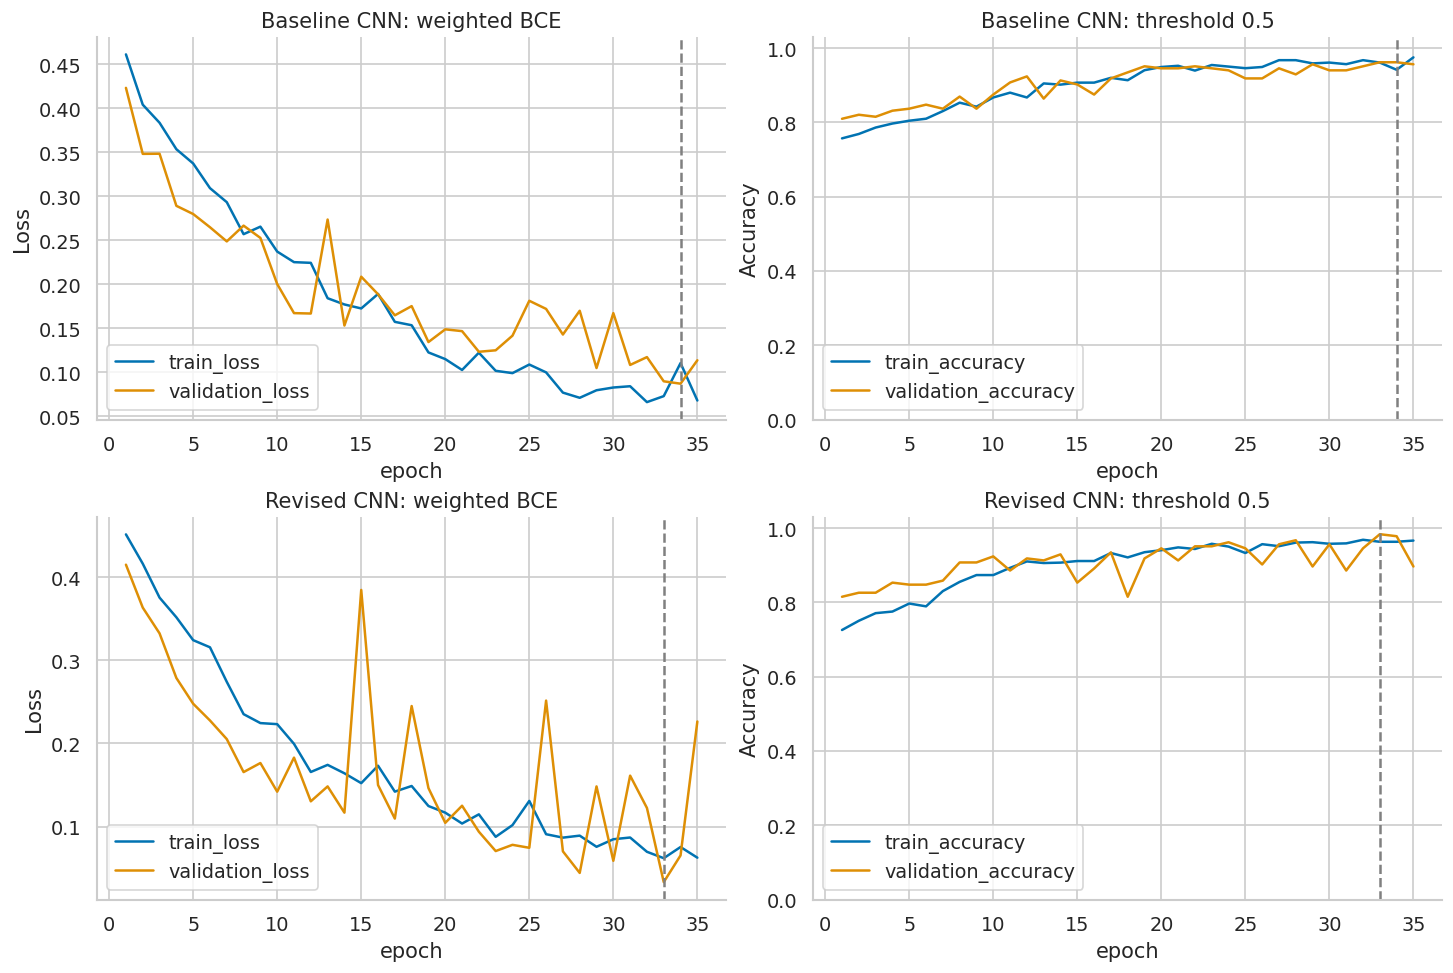

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, (name, history) in enumerate(histories.items()):
    history.plot(x='epoch', y=['train_loss', 'validation_loss'], ax=axes[row, 0])
    history.plot(x='epoch', y=['train_accuracy', 'validation_accuracy'], ax=axes[row, 1])
    for ax in axes[row]:
        ax.axvline(epochs[name], color='gray', ls='--')
    axes[row, 0].set(title=f'{name}: weighted BCE', ylabel='Loss')
    axes[row, 1].set(title=f'{name}: threshold 0.5', ylabel='Accuracy', ylim=(0, 1.03))
save_figure('04_cnn_learning_curves')
print('Training curves include augmentation and dropout; validation curves use clean images in eval mode.')

In [24]:
def choose_threshold(y_true, probabilities):
    # Validation-only F2 selection weights recall more strongly than precision.
    precision, recall, thresholds = precision_recall_curve(y_true, probabilities)
    scores = 5 * precision[:-1] * recall[:-1] / (
        4 * precision[:-1] + recall[:-1] + 1e-12)
    best = np.flatnonzero(np.isclose(scores, scores.max()))[-1]
    return float(thresholds[best])

def metrics_row(name, truth, probability, threshold):
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(truth, prediction, labels=[0, 1]).ravel()
    return {'model': name, 'threshold': threshold,
            'accuracy': accuracy_score(truth, prediction),
            'balanced_accuracy': balanced_accuracy_score(truth, prediction),
            'precision_fail': precision_score(truth, prediction, zero_division=0),
            'recall_fail': recall_score(truth, prediction, zero_division=0),
            'f1_fail': f1_score(truth, prediction, zero_division=0),
            'f2_fail': fbeta_score(truth, prediction, beta=2, zero_division=0),
            'average_precision': average_precision_score(truth, probability),
            'roc_auc': roc_auc_score(truth, probability),
            'mcc': matthews_corrcoef(truth, prediction),
            'specificity': tn / (tn + fp), 'missed_failures': int(fn),
            'false_alarms': int(fp), 'true_failures': int(tp), 'true_pass': int(tn)}

In [25]:
def bootstrap_intervals(truth, probability, threshold, repeats=400):
    truth = np.asarray(truth)
    rng = np.random.default_rng(SEED)
    groups = [np.flatnonzero(truth == label) for label in [0, 1]]
    values = []
    for _ in range(repeats):
        idx = np.concatenate([rng.choice(g, len(g), replace=True) for g in groups])
        pred = probability[idx] >= threshold
        values.append([average_precision_score(truth[idx], probability[idx]),
                       recall_score(truth[idx], pred),
                       fbeta_score(truth[idx], pred, beta=2, zero_division=0)])
    bounds = np.quantile(values, [0.025, 0.975], axis=0)
    return pd.DataFrame(bounds.T, columns=['lower_95', 'upper_95'],
                        index=['average_precision', 'recall_fail', 'f2_fail'])

In [26]:
validation_probabilities, thresholds, validation_rows = {}, {}, []
for name, model in cnn_models.items():
    loss, probability, truth = evaluate_network(model, val_loader)
    validation_probabilities[name] = probability
    thresholds[name] = choose_threshold(truth, probability)
    row = metrics_row(name, truth, probability, thresholds[name])
    row.update(validation_loss=loss, best_epoch=epochs[name], training_seconds=seconds[name])
    validation_rows.append(row)
cnn_validation = pd.DataFrame(validation_rows)
selected_name = cnn_validation.sort_values(
    ['average_precision', 'validation_loss'], ascending=[False, True]).iloc[0]['model']
selected_cnn = cnn_models[selected_name]
display(cnn_validation.round(4))
print(f'Final architecture: {selected_name}, selected by validation AP then validation loss.')
cnn_validation.to_csv(OUT / 'validation_metrics.csv', index=False)

Final architecture: Revised CNN, selected by validation AP then validation loss.


,model,threshold,accuracy,balanced_accuracy,precision_fail,recall_fail,f1_fail,f2_fail,average_precision,roc_auc,mcc,specificity,missed_failures,false_alarms,true_failures,true_pass,validation_loss,best_epoch,training_seconds
0,Baseline CNN,0.2039,0.9620,0.9567,0.9561,0.982,0.9689,0.9767,0.9950,0.9916,0.9205,0.9315,2,5,109,68,0.0868,34,59.4126
1,Revised CNN,0.2405,0.9946,0.9932,0.9911,1.000,0.9955,0.9982,0.9998,0.9998,0.9887,0.9863,0,1,111,72,0.0334,33,99.6560


In [27]:
fit_diagnostics = []
for name, model in cnn_models.items():
    train_loss, train_prob, train_truth = evaluate_network(model, train_eval_loader)
    val_loss, val_prob, val_truth = evaluate_network(model, val_loader)
    train_acc = accuracy_score(train_truth, train_prob >= 0.5)
    val_acc = accuracy_score(val_truth, val_prob >= 0.5)
    gap = train_acc - val_acc
    fit_diagnostics.append({'model': name, 'clean_train_loss': train_loss,
                            'validation_loss': val_loss, 'clean_train_accuracy': train_acc,
                            'validation_accuracy': val_acc, 'accuracy_gap': gap,
                            'diagnostic': 'Possible overfitting: inspect curves' if gap > 0.05
                            else 'No large accuracy gap; inspect loss and absolute performance'})
diagnostics = pd.DataFrame(fit_diagnostics)
display(diagnostics.round(4))
diagnostics.to_csv(OUT / 'fit_diagnostics.csv', index=False)

,model,clean_train_loss,validation_loss,clean_train_accuracy,validation_accuracy,accuracy_gap,diagnostic
0,Baseline CNN,0.0430,0.0868,0.9838,0.9620,0.0218,No large accuracy gap; inspect loss and absolu...
1,Revised CNN,0.0186,0.0334,0.9957,0.9837,0.0120,No large accuracy gap; inspect loss and absolu...


### 8.1. Final Design Rationale

In [28]:
validation = pd.read_csv(OUT / 'validation_metrics.csv').set_index('model')
capacity = pd.read_csv(OUT / 'architecture_design.csv').set_index('model')
fit = pd.read_csv(OUT / 'fit_diagnostics.csv').set_index('model')
chosen = validation.sort_values(['average_precision', 'validation_loss'], ascending=[False, True]).index[0]
reduction = 1 - capacity.loc['Revised CNN', 'parameters'] / capacity.loc['Baseline CNN', 'parameters']
rationale = pd.Series({
    'Final design': chosen + ' selected before test evaluation',
    'Architecture change': 'A third convolution block and more filters learn wider surface context; adaptive pooling limits dense capacity',
    'Regularisation': 'Batch normalisation stabilises activations; dropout and weight decay constrain fitting',
    'Capacity': f'Revised CNN uses {reduction:.1%} fewer trainable parameters than the baseline',
    'Validation evidence': f"Selected AP {validation.loc[chosen, 'average_precision']:.4f}; weighted BCE {validation.loc[chosen, 'validation_loss']:.4f}",
    'Fit evidence': f"Clean training accuracy {fit.loc[chosen, 'clean_train_accuracy']:.1%}; validation accuracy {fit.loc[chosen, 'validation_accuracy']:.1%} at threshold 0.5",
    'Curve interpretation': 'Low checkpoint errors give no strong underfitting signal; validation-loss oscillation warrants early checkpoint selection',
    'Uncertainty': 'The small validation set and single random seed cannot rule out source-specific overfitting',
    'Score interpretation': 'Class-weighted sigmoid scores are not established calibrated failure probabilities',
}, name='Final CNN rationale')
display(rationale.to_frame())
rationale.to_csv(OUT / 'final_architecture_rationale.csv')

,Final CNN rationale
Final design,Revised CNN selected before test evaluation
Architecture change,A third convolution block and more filters lea...
Regularisation,Batch normalisation stabilises activations; dr...
Capacity,Revised CNN uses 67.2% fewer trainable paramet...
Validation evidence,Selected AP 0.9998; weighted BCE 0.0334
Fit evidence,Clean training accuracy 99.6%; validation accu...
Curve interpretation,Low checkpoint errors give no strong underfitt...
Uncertainty,The small validation set and single random see...
Score interpretation,Class-weighted sigmoid scores are not establis...


## 9. Frozen-Model Held-Out Test Evaluation

In [29]:
test_probabilities, test_rows = {}, []
for name, model in cnn_models.items():
    _, probability, truth = evaluate_network(model, test_loader)
    test_probabilities[name] = probability
    test_rows.append(metrics_row(name, truth, probability, thresholds[name]))
y_test = test_records['label'].to_numpy()
cnn_test = pd.DataFrame(test_rows)
display(cnn_test.round(4))
cnn_test.to_csv(OUT / 'test_metrics.csv', index=False)
predictions = test_records[['path', 'label']].copy()
for name, probability in test_probabilities.items():
    predictions[f'{name}_probability'] = probability
    predictions[f'{name}_prediction'] = (probability >= thresholds[name]).astype(int)
predictions.to_csv(OUT / 'test_predictions.csv', index=False)

,model,threshold,accuracy,balanced_accuracy,precision_fail,recall_fail,f1_fail,f2_fail,average_precision,roc_auc,mcc,specificity,missed_failures,false_alarms,true_failures,true_pass
0,Baseline CNN,0.2039,0.9211,0.9035,0.8898,0.9912,0.9378,0.9691,0.9968,0.9948,0.8398,0.8158,1,14,113,62
1,Revised CNN,0.2405,0.9474,0.9342,0.9194,1.0000,0.9580,0.9828,0.9996,0.9993,0.8935,0.8684,0,10,114,66


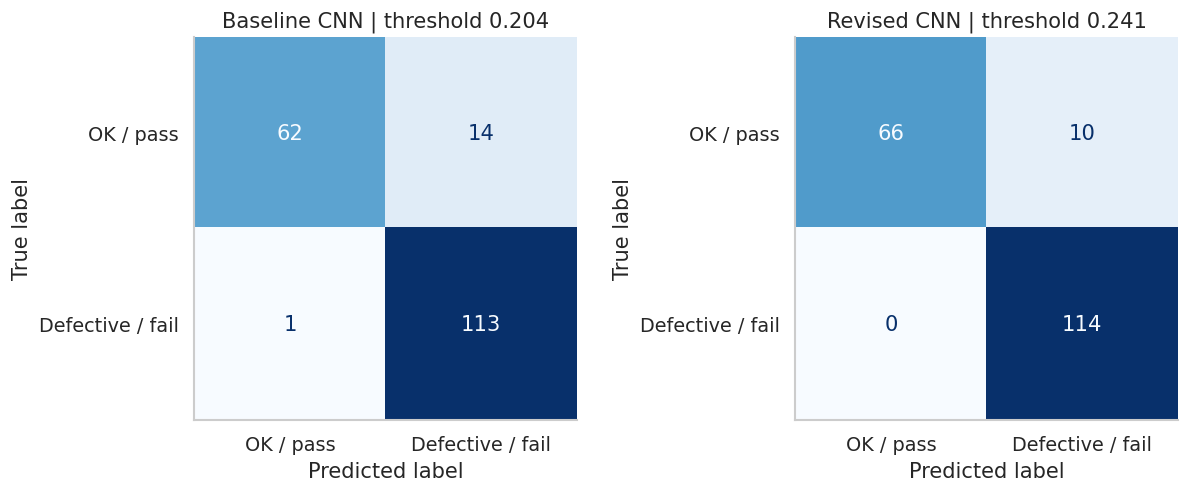

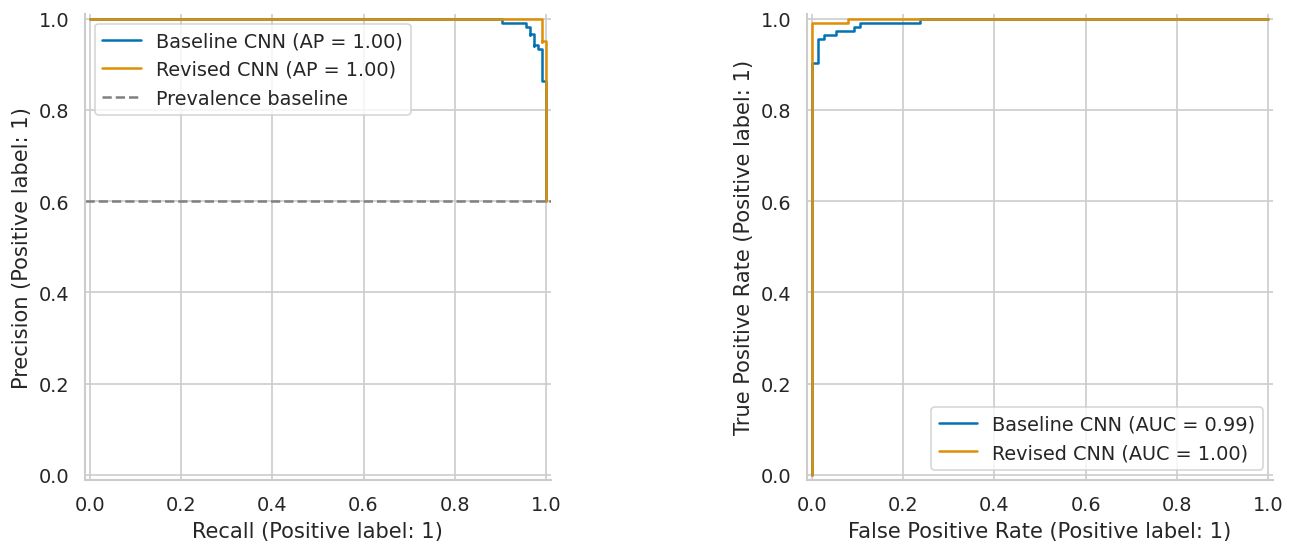

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, probability) in zip(axes, test_probabilities.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, probability >= thresholds[name], display_labels=['OK / pass', 'Defective / fail'],
        cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(f'{name} | threshold {thresholds[name]:.3f}')
    ax.grid(False)
save_figure('05_cnn_confusion_matrices')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, probability in test_probabilities.items():
    PrecisionRecallDisplay.from_predictions(y_test, probability, name=name, ax=axes[0])
    RocCurveDisplay.from_predictions(y_test, probability, name=name, ax=axes[1])
axes[0].axhline(y_test.mean(), color='gray', ls='--', label='Prevalence baseline')
axes[0].legend()
save_figure('06_cnn_pr_roc')

In [31]:
selected_probability = test_probabilities[selected_name]
selected_threshold = thresholds[selected_name]
selected_prediction = (selected_probability >= selected_threshold).astype(int)
report = pd.DataFrame(classification_report(
    y_test, selected_prediction, target_names=['OK / pass', 'Defective / fail'],
    output_dict=True, zero_division=0)).T
display(report.round(4))
report.to_csv(OUT / 'selected_cnn_classification_report.csv')
intervals = bootstrap_intervals(y_test, selected_probability, selected_threshold)
display(intervals.round(4))
intervals.to_csv(OUT / 'selected_cnn_bootstrap_intervals.csv')
print('Intervals condition on this image split; unknown batch identities and run-to-run variation are excluded.')

Intervals condition on this image split; unknown batch identities and run-to-run variation are excluded.


,precision,recall,f1-score,support
OK / pass,1.0000,0.8684,0.9296,76.0000
Defective / fail,0.9194,1.0000,0.9580,114.0000
accuracy,0.9474,0.9474,0.9474,0.9474
macro avg,0.9597,0.9342,0.9438,190.0000
weighted avg,0.9516,0.9474,0.9466,190.0000


,lower_95,upper_95
average_precision,0.9983,1.0000
recall_fail,1.0000,1.0000
f2_fail,0.9727,0.9913


## 10. Predictions, Errors and Visual Explanations

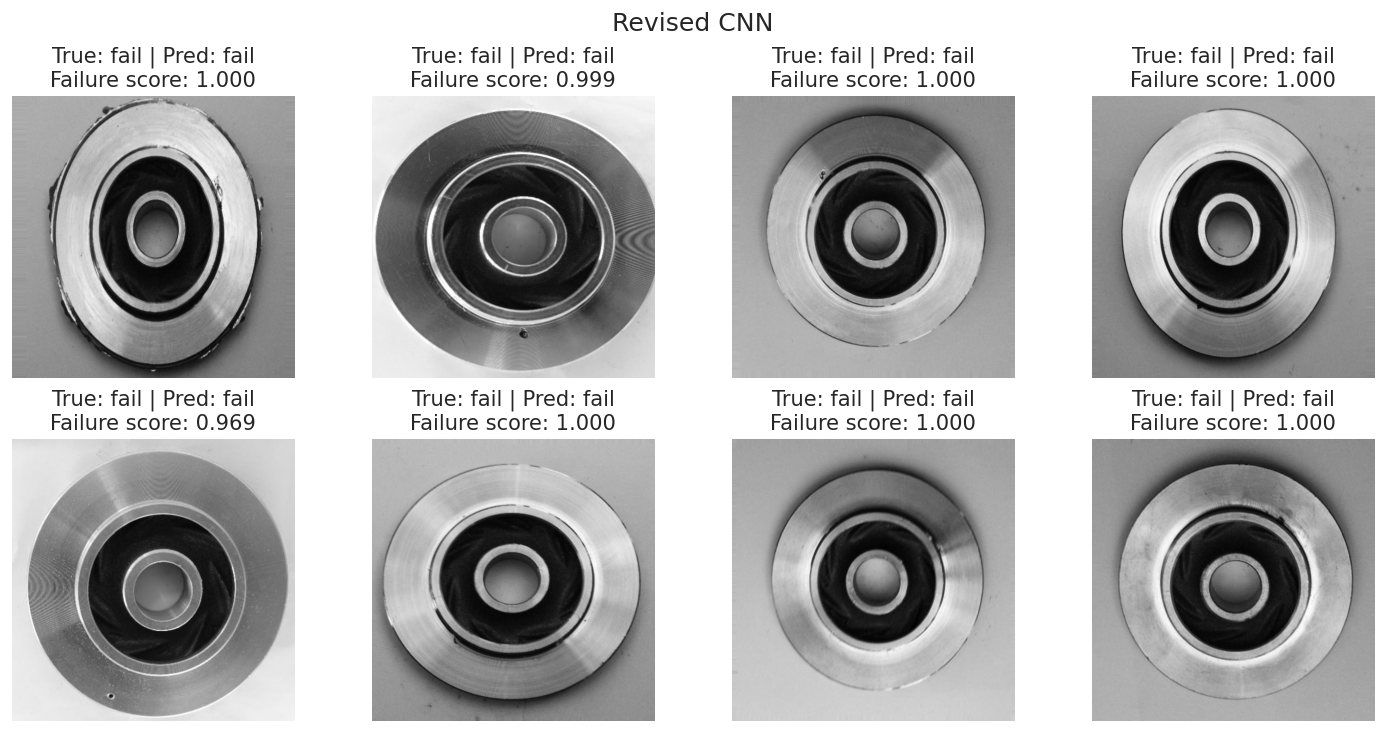

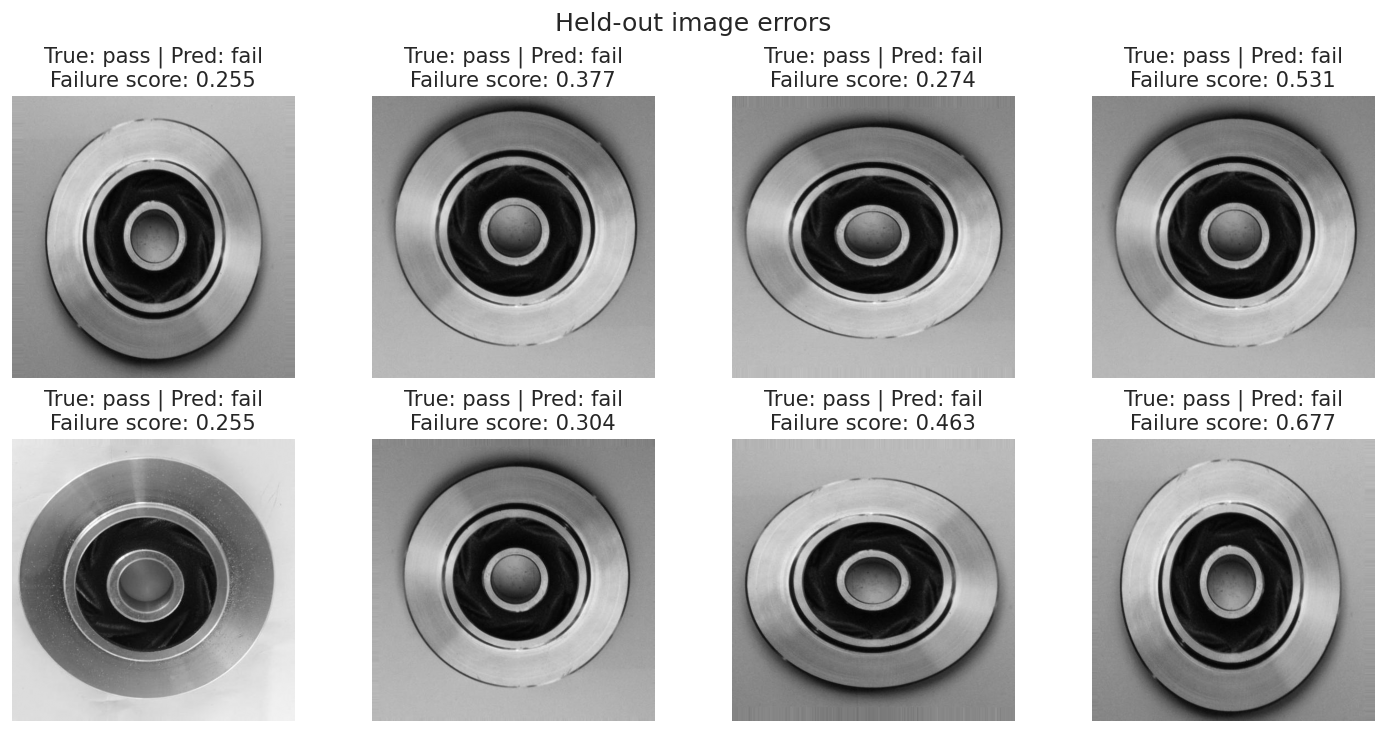

In [32]:
def plot_predictions(indices, filename, title):
    if len(indices) == 0:
        print('No cases in this category.')
        return
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for ax in axes.ravel():
        ax.axis('off')
    for ax, index in zip(axes.ravel(), indices[:8]):
        with Image.open(ROOT / test_records.iloc[index]['path']) as image:
            ax.imshow(image.convert('L'), cmap='gray')
        ax.set_title(f'True: {"fail" if y_test[index] else "pass"} | '
                     f'Pred: {"fail" if selected_prediction[index] else "pass"}\n'
                     f'Failure score: {selected_probability[index]:.3f}')
    fig.suptitle(title)
    save_figure(filename)

plot_predictions(np.arange(min(8, len(y_test))), '07_test_predictions', selected_name)
error_indices = np.flatnonzero(selected_prediction != y_test)
plot_predictions(error_indices, '08_test_errors', 'Held-out image errors')

Grad-CAM gives coarse sensitivity regions; it is not a validated defect segmentation or causal explanation.


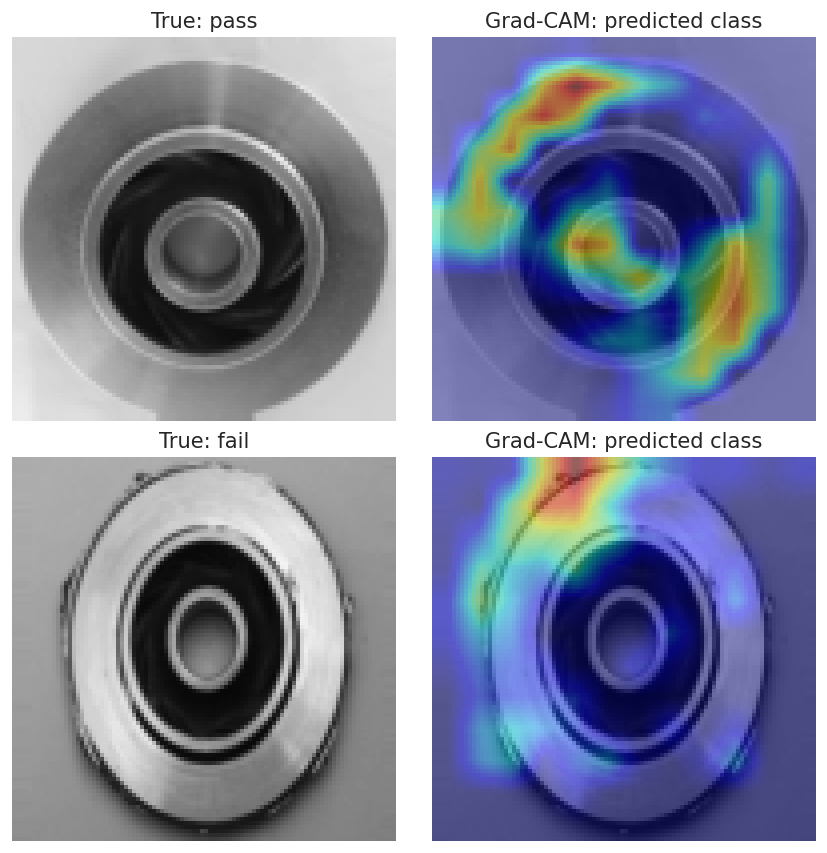

In [33]:
def grad_cam(model, tensor, target_label):
    model.eval()
    feature_map = model.features(tensor.to(DEVICE))
    logit = model.classifier(feature_map).squeeze()
    score = logit if target_label == 1 else -logit
    gradient = torch.autograd.grad(score, feature_map)[0]
    weights = gradient.mean(dim=(2, 3), keepdim=True)
    heatmap = torch.relu((weights * feature_map).sum(dim=1, keepdim=True))
    heatmap = torch.nn.functional.interpolate(
        heatmap, size=(IMAGE_SIZE, IMAGE_SIZE), mode='bilinear', align_corners=False)
    heatmap = heatmap.detach().cpu().numpy()[0, 0]
    return heatmap / (heatmap.max() + 1e-8)

cam_indices = [int(np.flatnonzero(y_test == label)[0]) for label in [0, 1]]
fig, axes = plt.subplots(2, 2, figsize=(7, 7))
for row, index in enumerate(cam_indices):
    tensor, _ = test_dataset[index]
    heatmap = grad_cam(selected_cnn, tensor.unsqueeze(0), int(selected_prediction[index]))
    image = tensor.squeeze().numpy() * 0.5 + 0.5
    axes[row, 0].imshow(image, cmap='gray', vmin=0, vmax=1)
    axes[row, 1].imshow(image, cmap='gray', vmin=0, vmax=1)
    axes[row, 1].imshow(heatmap, cmap='jet', alpha=0.45, vmin=0, vmax=1)
    axes[row, 0].set_title('True: ' + ('fail' if y_test[index] else 'pass'))
    axes[row, 1].set_title('Grad-CAM: predicted class')
for ax in axes.ravel():
    ax.axis('off')
save_figure('09_grad_cam')
print('Grad-CAM gives coarse sensitivity regions; it is not a validated defect segmentation or causal explanation.')

## 11. Saved Weights, Training Cost and Reloaded Inference

In [34]:
cnn_cost_rows = []
for name, model in cnn_models.items():
    path = MODELS / (name.lower().replace(' ', '_') + '.pt')
    torch.save({k: v.cpu() for k, v in model.state_dict().items()}, path)
    cnn_cost_rows.append({'model': name, 'training_seconds': seconds[name],
                          'total_search_seconds': sum(seconds.values()),
                          'parameters_or_nodes': sum(p.numel() for p in model.parameters()),
                          'capacity_unit': 'trainable parameters', 'file_bytes': path.stat().st_size})
cnn_cost = pd.DataFrame(cnn_cost_rows)
display(cnn_cost.round(3))
cnn_cost.to_csv(OUT / 'model_cost.csv', index=False)
pd.Series(thresholds, name='threshold').to_csv(MODELS / 'cnn_thresholds.csv')
pd.Series({'selected_architecture': selected_name, 'image_size': IMAGE_SIZE,
           'positive_label': 'defective', 'threshold': selected_threshold}).to_csv(MODELS / 'cnn_config.csv')

,model,training_seconds,total_search_seconds,parameters_or_nodes,capacity_unit,file_bytes
0,Baseline CNN,59.413,159.069,296225,trainable parameters,1188371
1,Revised CNN,99.656,159.069,97201,trainable parameters,397073


In [35]:
reloaded_cnn = architectures[selected_name]().to(DEVICE)
weight_path = MODELS / (selected_name.lower().replace(' ', '_') + '.pt')
reloaded_cnn.load_state_dict(torch.load(weight_path, map_location=DEVICE, weights_only=True))
_, reloaded_probability, _ = evaluate_network(reloaded_cnn, test_loader)
assert np.allclose(reloaded_probability, selected_probability, atol=1e-6)
display(pd.DataFrame({'actual': y_test[:5], 'failure_probability': reloaded_probability[:5],
                       'prediction': (reloaded_probability[:5] >= selected_threshold).astype(int)}))

,actual,failure_probability,prediction
0,1,1.000000,1
1,1,0.999153,1
2,1,0.999997,1
3,1,0.999808,1
4,1,0.969405,1


## 12. Part C: Classical Model, Feed-Forward Network and CNN

### 12.1. Measured Performance and Computational Requirements

In [36]:
sensor_results = pd.read_csv(ROOT / 'outputs' / 'part_a' / 'test_metrics.csv')
sensor_cost = pd.read_csv(ROOT / 'outputs' / 'part_a' / 'model_cost.csv')
sensor_splits = pd.read_csv(ROOT / 'outputs' / 'part_a' / 'split_summary.csv')
sensor_rows = sensor_results.merge(sensor_cost, on='model').assign(
    modality='Sensor / synthetic machine failure', train_samples=int(sensor_splits.iloc[0]['rows']),
    test_samples=int(sensor_splits.iloc[2]['rows']),
    test_prevalence=float(sensor_splits.iloc[2]['failure_rate']))
image_row = cnn_test[cnn_test['model'] == selected_name].merge(cnn_cost, on='model').assign(
    modality='Image / observed casting defect', train_samples=len(train_records),
    test_samples=len(test_records), test_prevalence=y_test.mean())
comparison = pd.concat([sensor_rows, image_row], ignore_index=True)
sensor_device = pd.read_csv(ROOT / 'outputs' / 'part_a' / 'environment.csv', index_col=0).loc['Device'].iloc[0]
comparison['training_device'] = [sensor_device, sensor_device, str(DEVICE)]
comparison['artifact_KiB'] = comparison['file_bytes'] / 1024
columns = ['model', 'modality', 'train_samples', 'test_samples', 'test_prevalence',
           'average_precision', 'recall_fail', 'precision_fail', 'f2_fail', 'accuracy',
           'training_seconds', 'total_search_seconds', 'parameters_or_nodes', 'capacity_unit', 'artifact_KiB']
display(comparison[columns].round(4))
comparison[columns + ['training_device']].to_csv(OUT / 'three_model_comparison.csv', index=False)
print('Different datasets, targets and prevalences prevent a fair cross-modality accuracy ranking.')
print('Timing is a single local run, not cloud cost; forest nodes and neural parameters are different units.')

Different datasets, targets and prevalences prevent a fair cross-modality accuracy ranking.
Timing is a single local run, not cloud cost; forest nodes and neural parameters are different units.


,model,modality,train_samples,test_samples,test_prevalence,average_precision,recall_fail,precision_fail,f2_fail,accuracy,training_seconds,total_search_seconds,parameters_or_nodes,capacity_unit,artifact_KiB
0,Random Forest,Sensor / synthetic machine failure,6000,2000,0.034,0.8972,0.8235,0.9032,0.8383,0.9910,1.0463,4.2890,26390,tree nodes,756.7432
1,Feed-forward MLP,Sensor / synthetic machine failure,6000,2000,0.034,0.7296,0.7941,0.5625,0.7337,0.9720,8.5791,8.5791,929,trainable parameters,6.4932
2,Revised CNN,Image / observed casting defect,926,190,0.600,0.9996,1.0000,0.9194,0.9828,0.9474,99.6560,159.0687,97201,trainable parameters,387.7666


### 12.2. Interpretability, Data Needs and Deployment Trade-Offs

In [37]:
tradeoffs = pd.DataFrame([
    {'method': 'Random Forest', 'interpretability': 'Validation permutation importance; individual trees inspectable',
     'data_requirements': 'Fixed tabular sensor schema; scarce labelled failures',
     'compute': 'CPU-friendly training; tree storage grows with ensemble size',
     'limitations': 'Synthetic failure rules; correlated-feature importance; cannot see surface defects'},
    {'method': 'Feed-forward MLP', 'interpretability': 'Weights are indirect; input sensitivity requires extra analysis',
     'data_requirements': 'Same sensor rows; training-fitted encoding and scaling',
     'compute': 'Small dense network; iterative optimisation and validation required',
     'limitations': 'Sensitive to scaling, class weight, seed and regularisation; cannot see surface defects'},
    {'method': selected_name, 'interpretability': 'Coarse Grad-CAM highlights; not defect segmentation',
     'data_requirements': 'Labelled product photographs; controlled camera, lighting and resolution',
     'compute': 'Convolutional training and image storage; GPU useful for larger datasets',
     'limitations': 'Single product and lighting regime; unverified batch separation; 96-pixel resizing can hide tiny flaws'},
])
display(tradeoffs)
tradeoffs.to_csv(OUT / 'critical_comparison.csv', index=False)

,method,interpretability,data_requirements,compute,limitations
0,Random Forest,Validation permutation importance; individual ...,Fixed tabular sensor schema; scarce labelled f...,CPU-friendly training; tree storage grows with...,Synthetic failure rules; correlated-feature im...
1,Feed-forward MLP,Weights are indirect; input sensitivity requir...,Same sensor rows; training-fitted encoding and...,Small dense network; iterative optimisation an...,"Sensitive to scaling, class weight, seed and r..."
2,Revised CNN,Coarse Grad-CAM highlights; not defect segment...,Labelled product photographs; controlled camer...,Convolutional training and image storage; GPU ...,Single product and lighting regime; unverified...


### 12.3. Evidence-Based SmartFactory Recommendation

In [38]:
sensor_validation = pd.read_csv(ROOT / 'outputs' / 'part_a' / 'validation_metrics.csv')
sensor_choice = sensor_validation.sort_values('average_precision', ascending=False).iloc[0]['model']
recommendation = pd.DataFrame([
    {'decision': 'Sensor monitoring pilot',
     'recommendation': sensor_choice + ' is the validation-AP leader; verify real process labels before deployment'},
    {'decision': 'Finished-product inspection pilot',
     'recommendation': selected_name + ' is the validation-selected casting architecture; retain manual review of uncertain cases'},
    {'decision': 'Combined SmartFactory workflow',
     'recommendation': 'Use sensor alarms upstream and visual inspection downstream as complementary checks; validate on paired production units'},
    {'decision': 'Performance and cost boundary',
     'recommendation': 'Do not average uncalibrated scores or infer fusion accuracy from unrelated datasets; measure actual missed-defect and review costs'},
    {'decision': 'Further validation',
     'recommendation': 'Collect independent batches, future time periods and changed lighting; repeat seeds and choose recall targets with the factory'},
    {'decision': 'Dataset reuse boundary',
     'recommendation': 'Casting photographs have a noncommercial licence; a commercial system needs an appropriate data basis'},
])
display(recommendation)
recommendation.to_csv(OUT / 'deployment_recommendation.csv', index=False)

,decision,recommendation
0,Sensor monitoring pilot,Random Forest is the validation-AP leader; ver...
1,Finished-product inspection pilot,Revised CNN is the validation-selected casting...
2,Combined SmartFactory workflow,Use sensor alarms upstream and visual inspecti...
3,Performance and cost boundary,Do not average uncalibrated scores or infer fu...
4,Further validation,"Collect independent batches, future time perio..."
5,Dataset reuse boundary,Casting photographs have a noncommercial licen...
